In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df=pd.read_csv("ToyotaCorolla - MLR.csv")
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [18]:
df.shape

(1436, 11)

In [19]:
df.columns

Index(['Price', 'Age_08_04', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc',
       'Doors', 'Cylinders', 'Gears', 'Weight'],
      dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


In [21]:
df.isnull().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

In [22]:
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


In [24]:
df["Price"].describe()

count     1436.000000
mean     10730.824513
std       3626.964585
min       4350.000000
25%       8450.000000
50%       9900.000000
75%      11950.000000
max      32500.000000
Name: Price, dtype: float64

In [26]:
df.select_dtypes(include="number").corr()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
Price,1.000000,-0.876590,-0.569960,0.314990,0.033081,0.126389,0.185326,NaN,0.063104,0.581198
Age_08_04,-0.876590,1.000000,0.505672,-0.156622,0.031717,-0.098084,-0.148359,NaN,-0.005364,-0.470253
KM,-0.569960,0.505672,1.000000,-0.333538,-0.081854,0.102683,-0.036197,NaN,0.015023,-0.028598
HP,0.314990,-0.156622,-0.333538,1.000000,0.013144,0.035856,0.092424,NaN,0.209477,0.089614
Automatic,0.033081,0.031717,-0.081854,0.013144,1.000000,0.066740,-0.027654,NaN,-0.098555,0.057249
cc,0.126389,-0.098084,0.102683,0.035856,0.066740,1.000000,0.079903,NaN,0.014629,0.335637
Doors,0.185326,-0.148359,-0.036197,0.092424,-0.027654,0.079903,1.000000,NaN,-0.160141,0.302618
Cylinders,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gears,0.063104,-0.005364,0.015023,0.209477,-0.098555,0.014629,-0.160141,NaN,1.000000,0.020613
Weight,0.581198,-0.470253,-0.028598,0.089614,0.057249,0.335637,0.302618,NaN,0.020613,1.000000


In [27]:
df.duplicated().sum()

1

In [28]:
df.drop_duplicates(inplace=True,ignore_index=True)

In [29]:
df.duplicated().sum()

0

In [43]:
features= df.drop("Price", axis=1)
target= df["Price"]

features.head()

,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,23,46986,Diesel,90,0,2000,3,4,5,1165
1,23,72937,Diesel,90,0,2000,3,4,5,1165
2,24,41711,Diesel,90,0,2000,3,4,5,1165
3,26,48000,Diesel,90,0,2000,3,4,5,1165
4,30,38500,Diesel,90,0,2000,3,4,5,1170


In [42]:
target.head()

0    13500
1    13750
2    13950
3    14950
4    13750
Name: Price, dtype: int64

In [44]:
features["Fuel_Type"].value_counts()

Petrol    1264
Diesel     154
CNG         17
Name: Fuel_Type, dtype: int64

In [45]:
features= pd.get_dummies(features, columns=["Fuel_Type"], drop_first=True)

features.head()

,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight,Fuel_Type_Diesel,Fuel_Type_Petrol
0,23,46986,90,0,2000,3,4,5,1165,1,0
1,23,72937,90,0,2000,3,4,5,1165,1,0
2,24,41711,90,0,2000,3,4,5,1165,1,0
3,26,48000,90,0,2000,3,4,5,1165,1,0
4,30,38500,90,0,2000,3,4,5,1170,1,0


In [47]:
target.head()

0    13500
1    13750
2    13950
3    14950
4    13750
Name: Price, dtype: int64

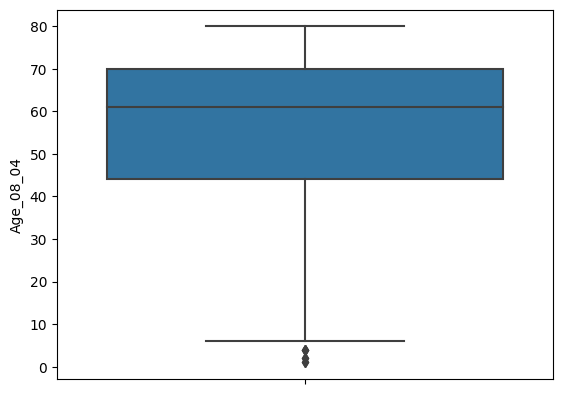

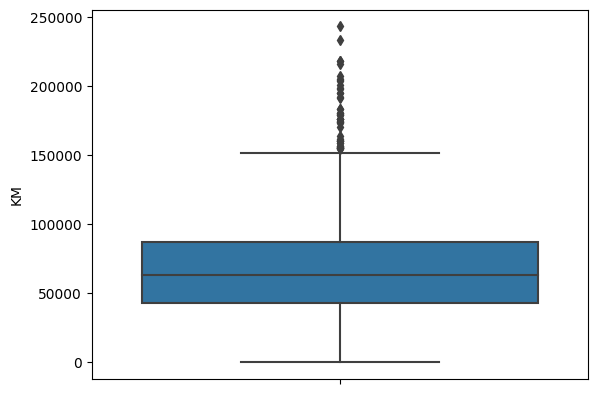

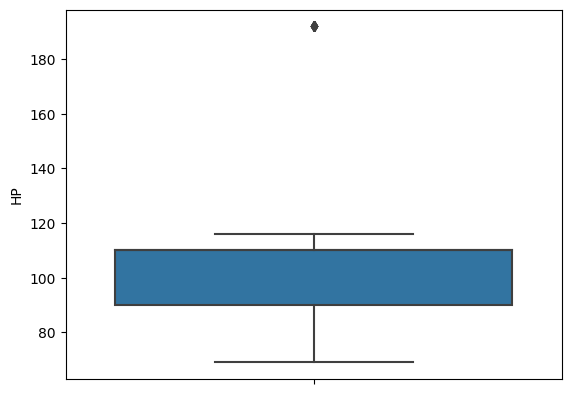

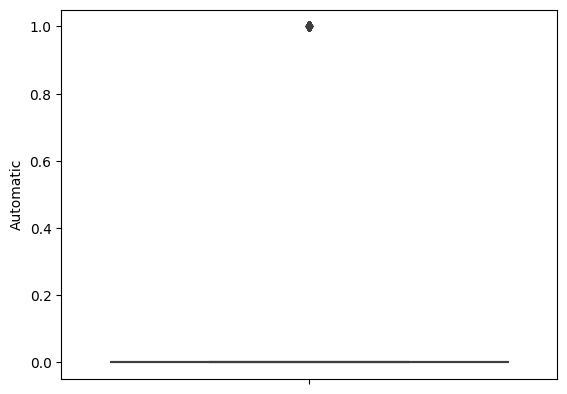

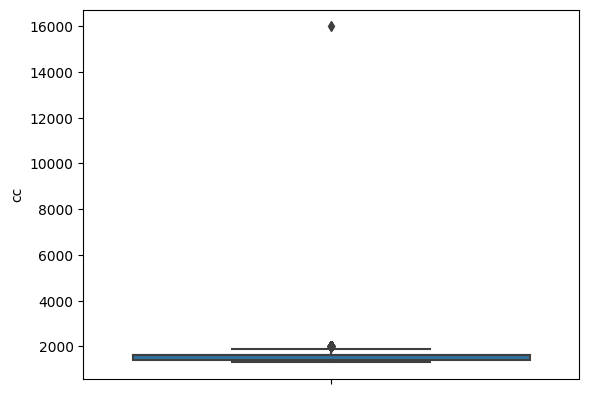

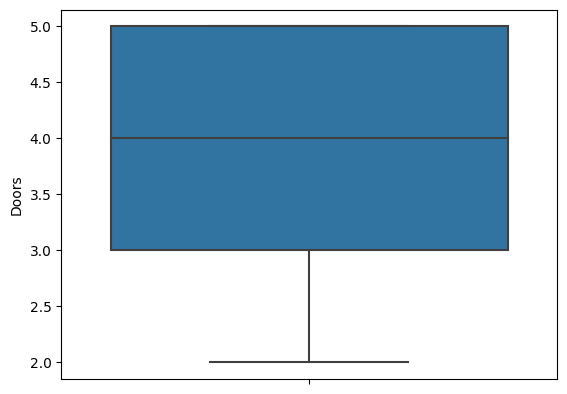

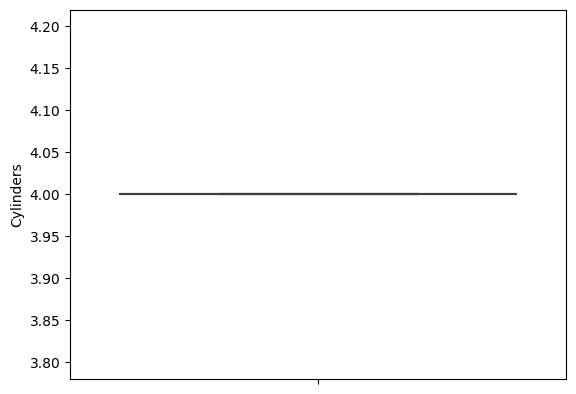

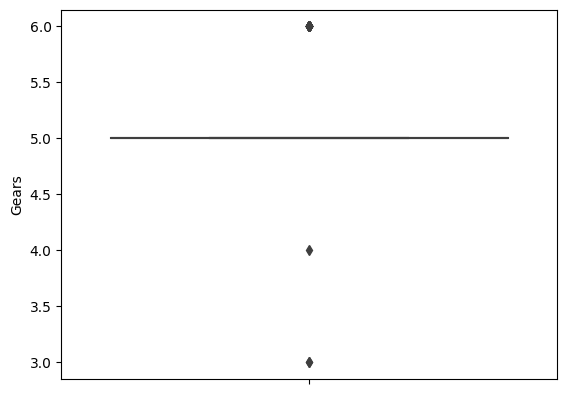

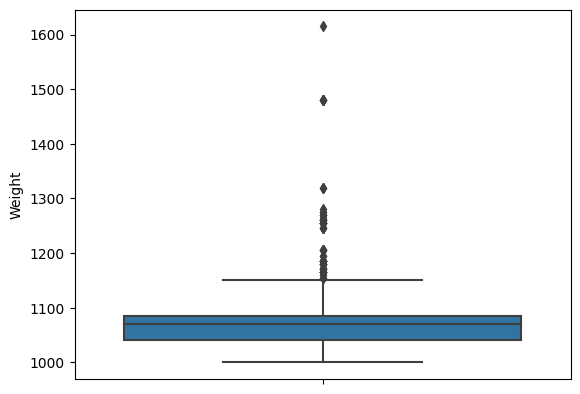

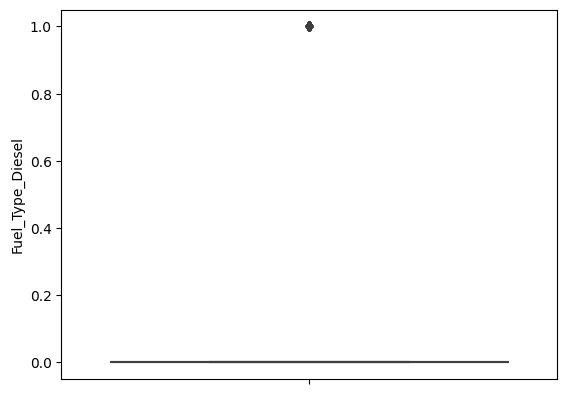

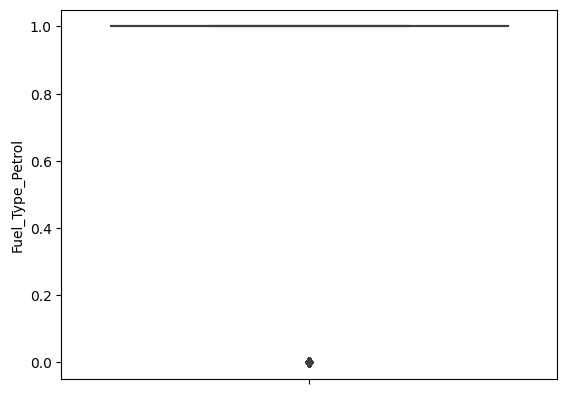

In [48]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

In [49]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

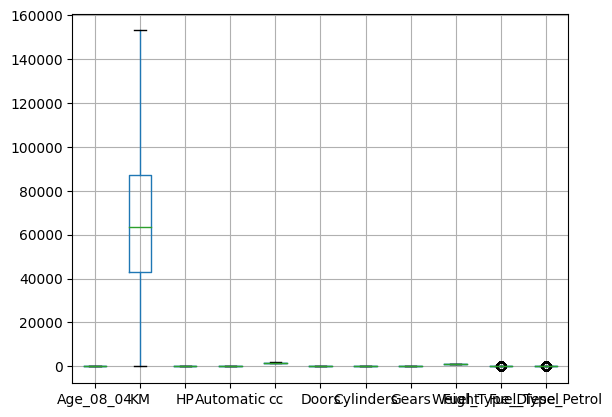

In [52]:
features.boxplot()
plt.show()

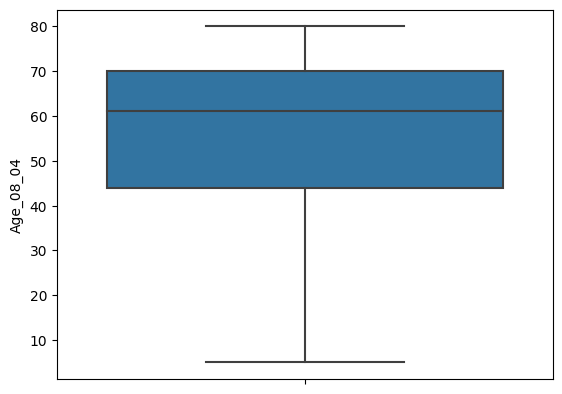

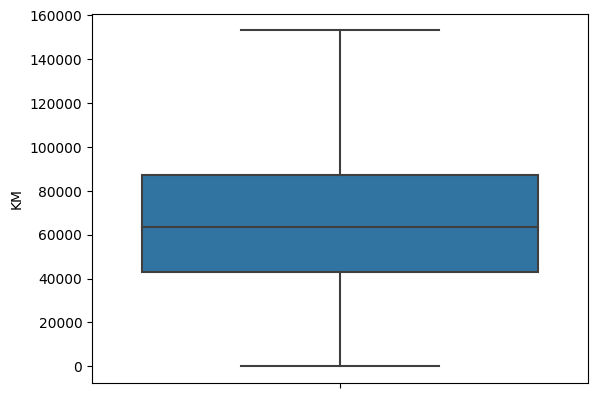

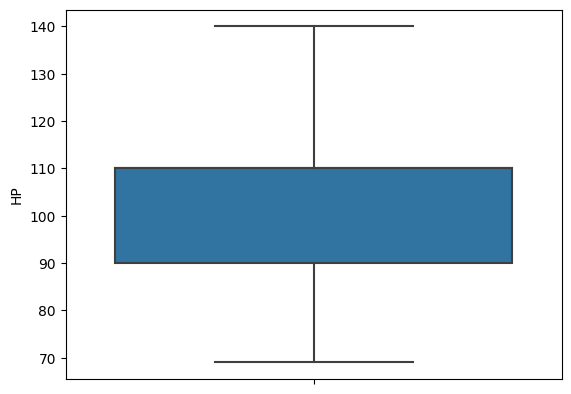

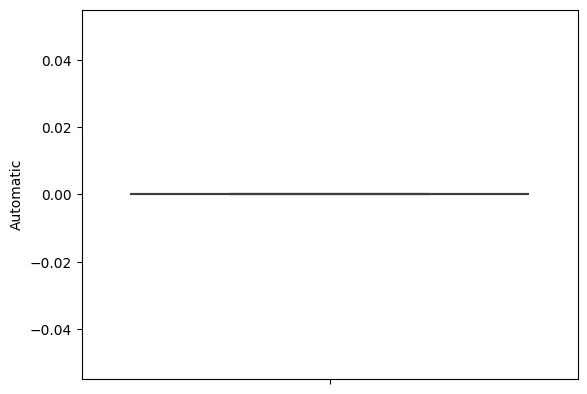

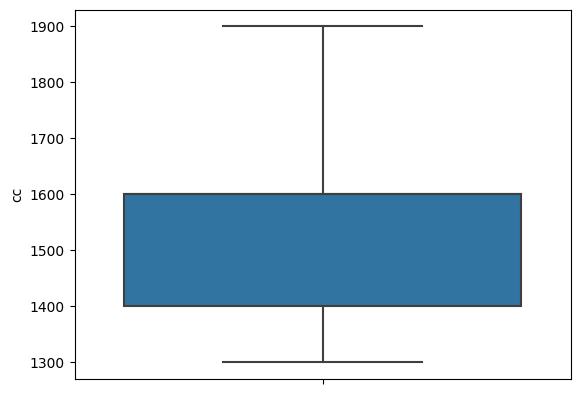

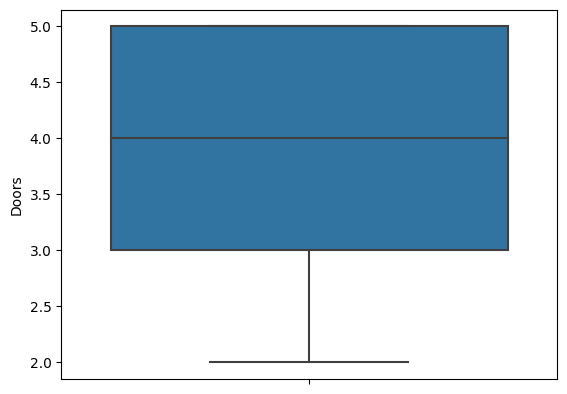

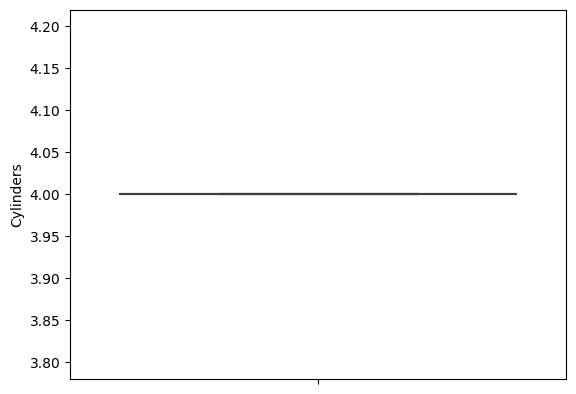

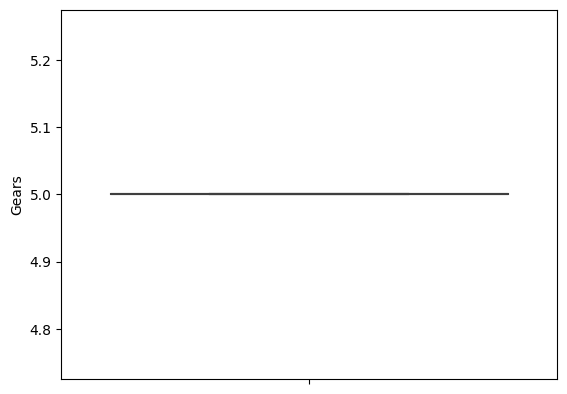

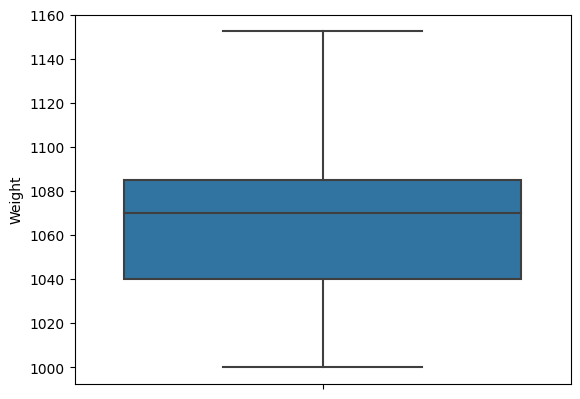

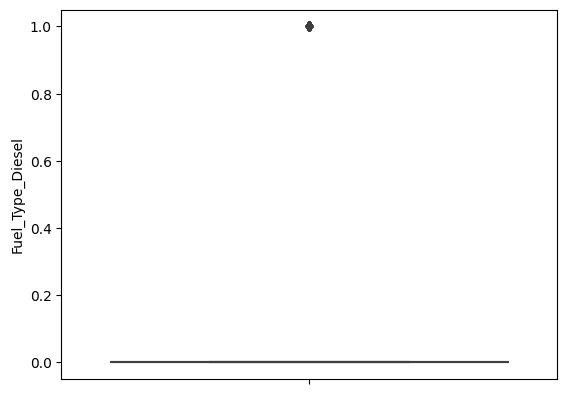

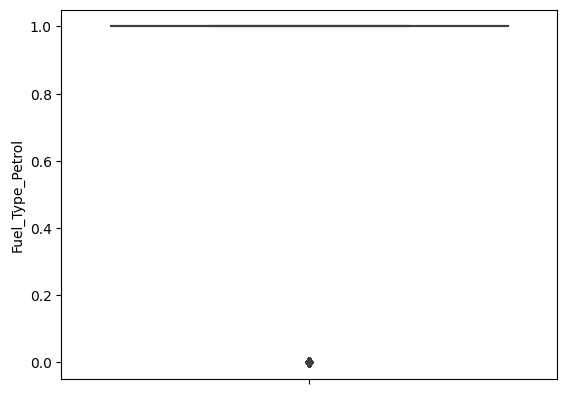

In [53]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

In [54]:
df1= pd.concat([features,target],axis=1)
df1.head()

,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight,Fuel_Type_Diesel,Fuel_Type_Petrol,Price
0,23.0,46986.0,90.0,0.0,1900.0,3,4,5.0,1152.5,1,0,13500
1,23.0,72937.0,90.0,0.0,1900.0,3,4,5.0,1152.5,1,0,13750
2,24.0,41711.0,90.0,0.0,1900.0,3,4,5.0,1152.5,1,0,13950
3,26.0,48000.0,90.0,0.0,1900.0,3,4,5.0,1152.5,1,0,14950
4,30.0,38500.0,90.0,0.0,1900.0,3,4,5.0,1152.5,1,0,13750


<AxesSubplot:>

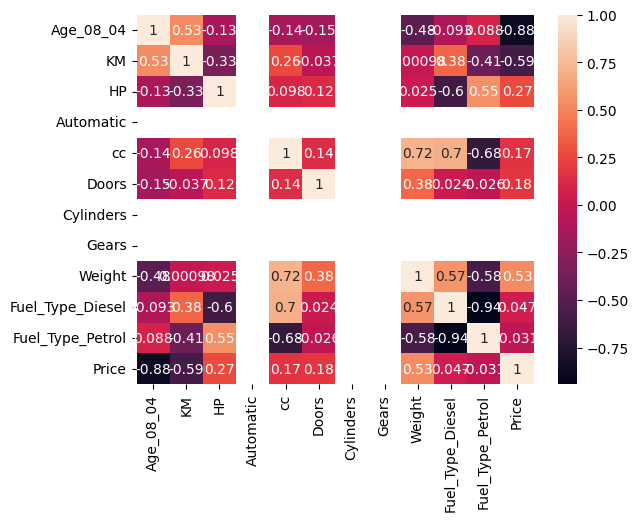

In [55]:
#### correlation
corr=df1.corr()
sns.heatmap(corr,annot=True)

c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:289: RuntimeWarning: divide by zero encountered in true_divide
  correlation_coefficient /= X_norms
c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:289: RuntimeWarning: invalid value encountered in true_divide
  correlation_coefficient /= X_norms
c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:358: RuntimeWarning: invalid value encountered in true_divide
  f_statistic = corr_coef_squared / (1 - corr_coef_squared) * deg_of_freedom


<AxesSubplot:>

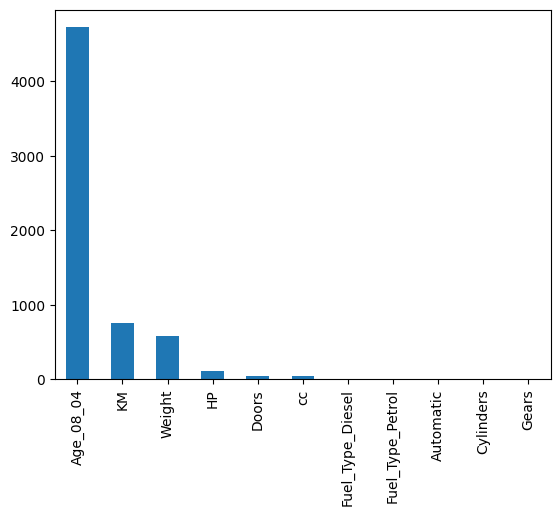

In [56]:
from sklearn.feature_selection import f_regression
f_reg=f_regression(features,target)
pd.Series(f_reg[0],index=features.columns).sort_values(ascending=False).plot(kind='bar')

c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:289: RuntimeWarning: divide by zero encountered in true_divide
  correlation_coefficient /= X_norms
c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:289: RuntimeWarning: invalid value encountered in true_divide
  correlation_coefficient /= X_norms
c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:358: RuntimeWarning: invalid value encountered in true_divide
  f_statistic = corr_coef_squared / (1 - corr_coef_squared) * deg_of_freedom


<AxesSubplot:>

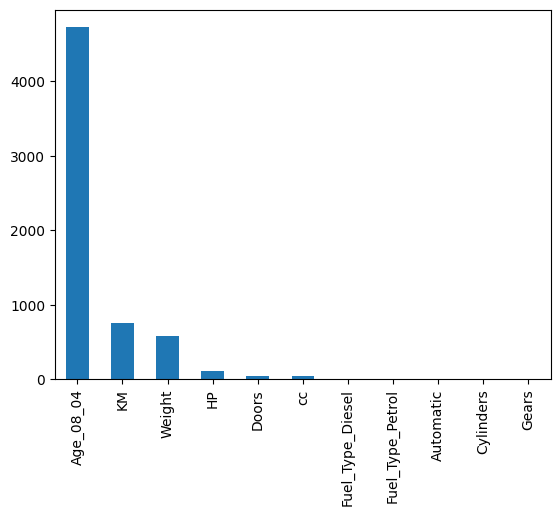

In [57]:
f_reg=f_regression(features,target)
pd.Series(f_reg[0],index=features.columns).sort_values(ascending=False).plot(kind='bar')

In [63]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
vif["Features"] = features.columns
vif["VIF_Scores"] = [
    variance_inflation_factor(features.values, i)
    for i in range(len(features.columns))
]

vif

c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\statsmodels\regression\linear_model.py:1752: RuntimeWarning: invalid value encountered in double_scalars
  return 1 - self.ssr/self.centered_tss
c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\statsmodels\regression\linear_model.py:1752: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - self.ssr/self.centered_tss


,Features,VIF_Scores
0,Age_08_04,2.181306
1,KM,2.015390
2,HP,10.104386
3,Automatic,NaN
4,cc,12.807789
5,Doors,1.302842
6,Cylinders,0.000000
7,Gears,0.000000
8,Weight,3.853438
9,Fuel_Type_Diesel,26.769346


In [65]:
features.values

array([[2.3000e+01, 4.6986e+04, 9.0000e+01, ..., 1.1525e+03, 1.0000e+00,
        0.0000e+00],
       [2.3000e+01, 7.2937e+04, 9.0000e+01, ..., 1.1525e+03, 1.0000e+00,
        0.0000e+00],
       [2.4000e+01, 4.1711e+04, 9.0000e+01, ..., 1.1525e+03, 1.0000e+00,
        0.0000e+00],
       ...,
       [7.1000e+01, 1.7016e+04, 8.6000e+01, ..., 1.0150e+03, 0.0000e+00,
        1.0000e+00],
       [7.0000e+01, 1.6916e+04, 8.6000e+01, ..., 1.0150e+03, 0.0000e+00,
        1.0000e+00],
       [7.6000e+01, 1.0000e+00, 1.1000e+02, ..., 1.1140e+03, 0.0000e+00,
        1.0000e+00]])

In [67]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

In [68]:
x_train,x_test,y_train,y_test=train_test_split(features,target,train_size=0.8,random_state=100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1148, 11)
(287, 11)
(1148,)
(287,)


In [71]:
model1 = LinearRegression()

model1.fit(x_train, y_train)

LinearRegression()

In [73]:
y_pred1 = model1.predict(x_test)

y_pred1[:10]

array([16353.65691663, 10778.28078727, 13167.21277136, 10375.8241314 ,
        8200.2956484 ,  9331.79330785, 13634.93037432,  7166.48344981,
       13108.25656094,  8704.04845233])

In [75]:
r2_model1 = model1.score(x_test, y_test)

r2_model1

0.8522280048101063

In [76]:
from sklearn.metrics import mean_absolute_error

mae_model1 = mean_absolute_error(y_test, y_pred1)

mae_model1


960.7156939522421

In [77]:
from sklearn.metrics import mean_squared_error

rmse_model1 = np.sqrt(mean_squared_error(y_test, y_pred1))

rmse_model1

1327.9801344049624

In [87]:
#### Testing Validation

y_pred1= model1.predict(x_test)

r2_score(y_test,y_pred1)

0.8522280048101063

<AxesSubplot:xlabel='Price'>

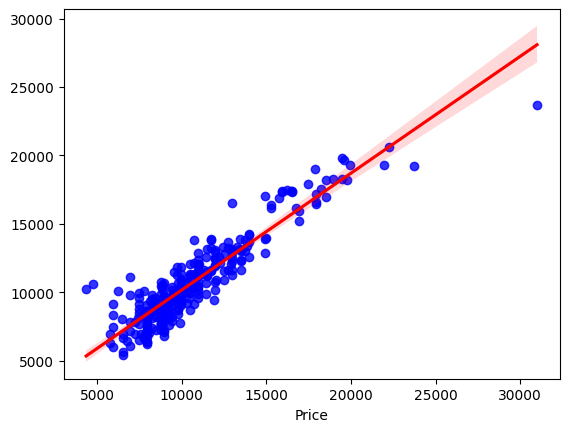

In [88]:
sns.regplot(x=y_test,y=y_pred1,line_kws={'color':'red'},scatter_kws={'color':'blue'})